In [9]:
import torch
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
# import plotly.graph_objects as go

In [3]:
strings = torch.tensor([
    [100, 100, 0], [202, 205, 0], [80, 202, 0], [14, 210, 0], [11, 11, 0],
    [180, 60, 0], [82, 85, 0], [78, 82, 0], [69, 50, 0], [180, 81, 0]
], dtype=torch.float32)
N_strings=strings.shape[0]

In [4]:
C_cable=200
C_cjb=150e3
cjb_capacity=8
max_cjbs=10

In [5]:
cjbs = torch.tensor([
    [0, 0, 0], [20, 20, 0], [50, 50, 0],
    [70, 70, 0], [100, 100, 0], [130, 130, 0],
    [160, 160, 0], [190, 190, 0], [220, 220, 0], [250, 250, 0
]], dtype=torch.float32, requires_grad=True)

In [ ]:
#optimizer=optim.Adam([cjbs], lr=1)

In [ ]:
#def hungarian_algorithm(strings, cjbs):
 # dists=torch.cdist(strings, cjbs).detach().numpy()
 # expanded_dists=np.repeat(dists, cjb_capacity, axis=1)
 # cost_matrix=expanded_dists*C_cable
 # string_indices, slot_indices=linear_sum_assignment(cost_matrix)
 # cjb_assignments=slot_indices//cjb_capacity
  #print(string_indices, slot_indices)
 # return cjb_assignments


In [6]:
def soft_assignment(strings, cjbs, beta=1.0):

    dists = torch.cdist(strings, cjbs)

    assignment_weights = torch.softmax(-beta * dists, dim=1)

    return assignment_weights

In [8]:
soft_assignments = soft_assignment(strings, cjbs)
soft_assignments.shape

torch.Size([10, 10])

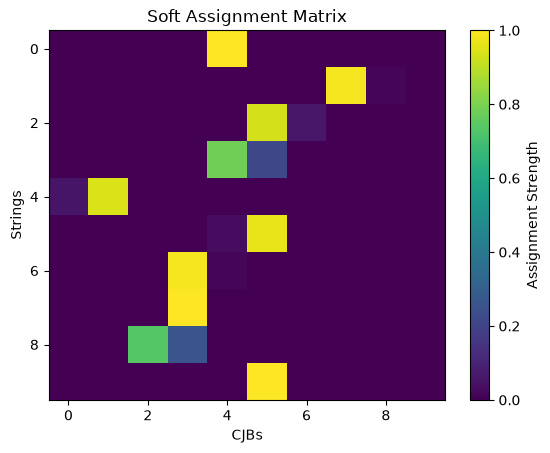

In [12]:
# plot of 10x10 soft assignment matrix
plt.imshow(soft_assignments.detach().numpy(), cmap='viridis', aspect='auto')
plt.xlabel('CJBs')
plt.ylabel('Strings')
plt.title('Soft Assignment Matrix')
plt.colorbar(label='Assignment Strength')


In [13]:
optimizer = optim.Adam([cjbs], lr=1)


beta = 0.05

history_cjbs = [cjbs.detach().clone().numpy()]
history_weights = []

for i in range(1000):
    optimizer.zero_grad()

    weights = soft_assignment(strings, cjbs, beta=beta)
    assigned_cjbs = torch.matmul(weights, cjbs)

    cable_lengths = torch.norm(strings - assigned_cjbs, dim=1)
    cable_cost = C_cable * torch.sum(cable_lengths)

    cjb_usage = torch.sum(weights, dim=0)
    soft_active_cjbs = torch.sum(torch.tanh(cjb_usage * 2.0))
    number_of_cjb_cost = C_cjb * soft_active_cjbs

    loss = cable_cost + number_of_cjb_cost
    loss.backward()


    optimizer.step()


    if (i + 1) % 100 == 0:
        beta *= 1.3
        print(f"Epoch {i + 1} | Loss: {loss.item():.2f} | Soft Active CJBs: {soft_active_cjbs.item():.2f} | Beta: {beta:.3f}")

history_cjbs.append(cjbs.detach().clone().numpy())
history_weights.append(weights.detach().clone().numpy())

Epoch 100 | Loss: 848175.12 | Soft Active CJBs: 5.47 | Beta: 0.065
Epoch 200 | Loss: 786286.81 | Soft Active CJBs: 5.05 | Beta: 0.085
Epoch 300 | Loss: 773843.12 | Soft Active CJBs: 4.96 | Beta: 0.110
Epoch 400 | Loss: 770453.38 | Soft Active CJBs: 4.94 | Beta: 0.143
Epoch 500 | Loss: 769786.50 | Soft Active CJBs: 4.93 | Beta: 0.186
Epoch 600 | Loss: 769698.62 | Soft Active CJBs: 4.93 | Beta: 0.241
Epoch 700 | Loss: 769681.81 | Soft Active CJBs: 4.93 | Beta: 0.314
Epoch 800 | Loss: 769681.44 | Soft Active CJBs: 4.93 | Beta: 0.408
Epoch 900 | Loss: 769685.44 | Soft Active CJBs: 4.93 | Beta: 0.530
Epoch 1000 | Loss: 769673.38 | Soft Active CJBs: 4.93 | Beta: 0.689


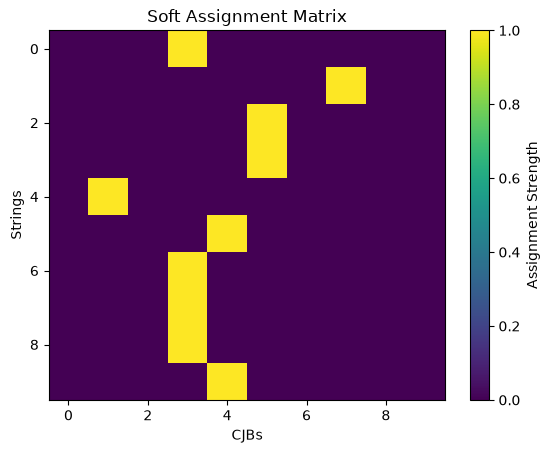

In [14]:
plt.imshow(history_weights[-1], aspect='auto')
plt.xlabel('CJBs')
plt.ylabel('Strings')
plt.title('Soft Assignment Matrix')
plt.colorbar(label='Assignment Strength')

In [ ]:
hungarian_algorithm(strings, cjbs)

array([3, 7, 5, 5, 1, 4, 3, 3, 3, 4])

In [ ]:
#for i in range(1000):
 # optimizer.zero_grad()
 # cjb_indices=hungarian_algorithm(strings, cjbs)
 # assigned_cjbs=cjbs[cjb_indices]
 # cable_lengths=torch.norm(strings-assigned_cjbs, dim=1)
 # cable_cost=C_cable*torch.sum(cable_lengths)

 # unique_active_cjbs=torch.unique(torch.tensor(cjb_indices))
 # number_of_cjb_cost=C_cjb*len(unique_active_cjbs)
 # loss=cable_cost + number_of_cjb_cost
 # loss.backward()
 # optimizer.step()


 # if (i+1)%100==0:
  #  print(f"Epoch {i + 1}")
  #  print(f"  Loss: {loss.item():.5f}")
  #  print(f"  Cable Length: {cable_lengths.sum().item():.1f}m")
  #  print(f"  Active CJBs: {len(unique_active_cjbs)}")
    #print(f"  New CJB Positions:\n{cjbs.detach().numpy()}")


In [ ]:
#unique_active=np.unique(hungarian_algorithm(strings,cjbs))
#for i in range (max_cjbs):
 # status = "active" if i in unique_active else "off"
 # n_cables=np.sum(hungarian_algorithm(strings, cjbs) == i)
 # pos = cjbs[i].detach().numpy().round(1)

In [ ]:
#import plotly.graph_objects as go

#strings_np=strings.detach().numpy()
#cjbs_np=cjbs.detach().numpy()
#fig=go.Figure()
#fig.add_trace(go.Scatter(
 #   x=strings_np[:, 0], y=strings_np[:, 1], mode="markers", marker=dict(size=5, color="red"), name=f"Strings ({N_strings})"))
#active_cjbs_np=cjbs_np[unique_active]
#fig.add_trace(go.Scatter(
 #   x=active_cjbs_np[:, 0], y=active_cjbs_np[:, 1],
 #  mode='markers',
 #  marker=dict(size=10, color='gold', symbol='diamond', line=dict(color='black', width=2)),
 #  name=f'Active CJBs ({len(unique_active)})'))
#cable_x, cable_y = [], []
#for s_idx, cjb_idx in enumerate(hungarian_algorithm(strings, cjbs)):
 #   s_pos = strings_np[s_idx]
  #  c_pos = cjbs_np[cjb_idx]
   # cable_x.extend([s_pos[0], c_pos[0], None])
    #cable_y.extend([s_pos[1], c_pos[1], None])
#fig.add_trace(go.Scatter(
 #   x=cable_x, y=cable_y,
  #  mode='lines',
   # line=dict(color='gray', width=1.5),
    #opacity=0.6,
    #name='Discrete Cable Assignments'))
#fig.update_layout(
 #   title=f"Hungarian Algorithm + PyTorch Optimization<br>Active CJBs: {len(unique_active)}/{max_cjbs} | Total Cost: ${loss.item():,.2f}",
  #  xaxis_title='X (meters)', yaxis_title='Y (meters)',
   # margin=dict(l=0, r=0, b=0, t=50))
#fig.show()


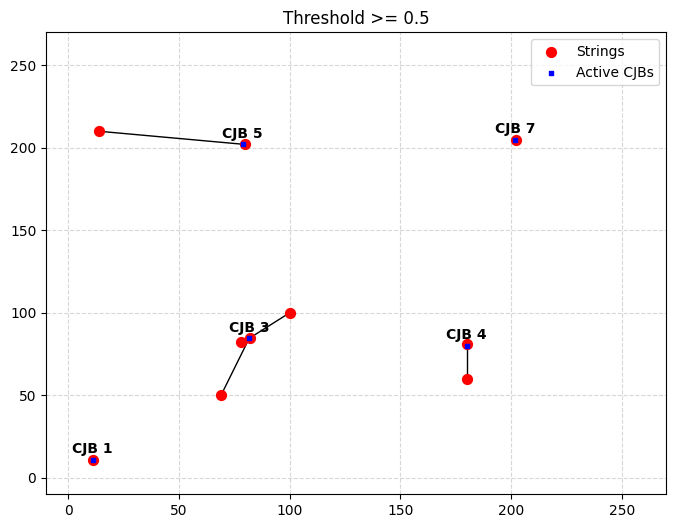

In [ ]:
strings_np = strings.detach().cpu().numpy()
end_cjbs = history_cjbs[-1]

threshold = 0.5
final_weights = history_weights[-1]
cjb_usage_final = final_weights.sum(axis=0)

active_cjb_mask = cjb_usage_final >= threshold
active_cjb_indices = np.where(active_cjb_mask)[0]

hard_assignments = []
for s_idx in range(N_strings):
    best_cjb = np.argmax(final_weights[s_idx])
    if best_cjb in active_cjb_indices:
        hard_assignments.append(best_cjb)
    else:
        active_weights = final_weights[s_idx] * active_cjb_mask
        if np.sum(active_weights) > 0:
            hard_assignments.append(np.argmax(active_weights))
        else:
            hard_assignments.append(best_cjb)

hard_assignments = np.array(hard_assignments)


plt.figure(figsize=(8, 6))

for s_idx, cjb_idx in enumerate(hard_assignments):
    s_pos = strings_np[s_idx]
    c_pos = end_cjbs[cjb_idx]
    plt.plot([s_pos[0], c_pos[0]], [s_pos[1], c_pos[1]], color='black', linestyle='-', linewidth=1)

plt.scatter(strings_np[:, 0], strings_np[:, 1], color='red', s=50, label='Strings', zorder=5)

plt.scatter(end_cjbs[active_cjb_indices, 0], end_cjbs[active_cjb_indices, 1],
            color='blue', marker='s', s=10, label='Active CJBs', zorder=6)

for idx in active_cjb_indices:
    plt.text(end_cjbs[idx, 0], end_cjbs[idx, 1] + 4, f"CJB {idx}",
             fontsize=10, fontweight='bold', ha='center')

plt.title(f"Threshold >= {threshold}")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim(-10, 270)
plt.ylim(-10, 270)
plt.show()